#Paquetes necesarios

In [1]:
import cv2  
import math 

from ultralytics import YOLO

Modelos preentrenados, visualizando con las utilidades de ultralytics

In [2]:
# Carga del modelo
model = YOLO('YOLO/yolo11s.pt') #Contenedores

#Para un vídeo 
filename = "TGC23_PdH_C0056cut.mp4"
results = model(filename, show=True)

cv2.destroyAllWindows()

WARNING Environment does not support cv2.imshow() or PIL Image.show()
OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:1215: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'showImageImpl'


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/375) c:\Uni\VC\practi

KeyboardInterrupt: 

Desde cámara, detección con yolo11, modelo nano. Visualización propia con OpenCV

In [ ]:
# Carga del modelo, descarga en disco si no está presente en la carpeta
model = YOLO('YOLO/yolo11s.pt') #Contenedores

# Etiqueta de las distintas clases
classNames = ["person", "bicycle", "car", "motorbike", "aeroplane", "bus", "train", "truck", "boat",
              "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat",
              "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella",
              "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball", "kite", "baseball bat",
              "baseball glove", "skateboard", "surfboard", "tennis racket", "bottle", "wine glass", "cup",
              "fork", "knife", "spoon", "bowl", "banana", "apple", "sandwich", "orange", "broccoli",
              "carrot", "hot dog", "pizza", "donut", "cake", "chair", "sofa", "pottedplant", "bed",
              "diningtable", "toilet", "tvmonitor", "laptop", "mouse", "remote", "keyboard", "cell phone",
              "microwave", "oven", "toaster", "sink", "refrigerator", "book", "clock", "vase", "scissors",
              "teddy bear", "hair drier", "toothbrush"
              ]


# Captura desde la webcam
vid = cv2.VideoCapture("C0142.mp4")
  
while(True):      
    # fotograma a fotograma
    ret, img = vid.read()
  
    # si hay imagen válida
    if ret:  
        # Detecta en la imagen
        results = model(img, stream=True)
        
        # Para cada detección
        for r in results:
            boxes = r.boxes

            for box in boxes:
                # Contenedor
                x1, y1, x2, y2 = box.xyxy[0]
                x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2) # convert to int values
                
                # Confianza
                confidence = math.ceil((box.conf[0]*100))/100
                print("Confianza --->",confidence)

                # Clase
                cls = int(box.cls[0])
                print("Clase -->", classNames[cls])

                # Convierte identificador numérico de clase a un color RGB
                escala = int((cls / len(classNames)) * 255 * 3)
                if escala >= 255*2:
                    R = 255
                    G = 255
                    B = escala - 255*2
                else:
                    if escala >= 255:
                        R = 255
                        G = escala - 255
                        B = 0
                    else:
                        R = escala
                        G = 0
                        B = 0

                # Dibuja el contenedor y clase
                cv2.rectangle(img, (x1, y1), (x2, y2), (R, G, B), 3)
                cv2.putText(img, classNames[cls] , [x1, y1], cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, B), 2)

        # Muestra fotograma
        cv2.imshow('Vid', img)
    
    # Detenemos pulsado ESC
    if cv2.waitKey(20) == 27:
        break
  
# Libera el objeto de captura
vid.release()
# Destruye ventanas
cv2.destroyAllWindows()


0: 384x640 2 persons, 5 cars, 1 bus, 1 bench, 14.6ms
Confianza ---> 0.96
Clase --> bus
Confianza ---> 0.85
Clase --> car
Confianza ---> 0.62
Clase --> bench
Confianza ---> 0.56
Clase --> car
Confianza ---> 0.55
Clase --> car
Confianza ---> 0.37
Clase --> person
Confianza ---> 0.35
Clase --> person
Confianza ---> 0.29
Clase --> car
Confianza ---> 0.28
Clase --> car
Speed: 3.7ms preprocess, 14.6ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 3 cars, 1 bus, 1 bench, 26.3ms
Confianza ---> 0.96
Clase --> bus
Confianza ---> 0.85
Clase --> car
Confianza ---> 0.65
Clase --> bench
Confianza ---> 0.55
Clase --> car
Confianza ---> 0.52
Clase --> car
Confianza ---> 0.45
Clase --> person
Speed: 1.9ms preprocess, 26.3ms inference, 2.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 person, 3 cars, 1 bus, 1 bench, 1 potted plant, 26.1ms
Confianza ---> 0.96
Clase --> bus
Confianza ---> 0.84
Clase --> car
Confianza ---> 0.68
Clase --> person
Co

## 2. Dataset y entrenamiento de YOLO11s

### 2.1 Dataset con la misma división que RT-DETRv2-S

Para que la comparación con RT-DETRv2-S sea justa, YOLO11s se entrena con **las mismas imágenes, cajas y división**.
La celda repite la Fase 1 de `VC_P4_RTDETR` sobre el dataset original (`C:/Uni/VC/P4_dataset_original`) y guarda el
resultado en formato YOLO en `C:/Uni/VC/P4_dataset`, que es la carpeta a la que apunta `YOLO/train.yaml`:

- **Rotación EXIF** aplicada y **reescalado** a 1280 px de lado mayor (sin ampliar las pequeñas).
- **Cajas giradas corregidas**: algunas fotos con EXIF de orientación 6 se anotaron sobre la imagen sin girar; se
  detectan por la proporción de sus cajas y se llevan a la imagen girada.
- Cajas de menos de 1 px **descartadas**.
- **División 60/15/25 por bloques** de 10 fotos consecutivas (mismo coche o escena), barajados con `SEED = 42`.
  Las fotos se ordenan por nombre sin distinguir mayúsculas, que es el orden de Windows con el que se hizo la
  división de RT-DETR.
- Etiquetas `0 cx cy w h` normalizadas, sacadas de la misma caja que la anotación COCO de RT-DETR.

Si `P4_dataset` contiene otra división, se borra antes de empezar. Si se vuelve a ejecutar con los mismos parámetros,
reutiliza las imágenes ya reescaladas. Al final comprueba que cada foto cae en el mismo conjunto que en `Dataset_coco`.

  250/2418 imágenes procesadas
  500/2418 imágenes procesadas
  750/2418 imágenes procesadas
  1000/2418 imágenes procesadas
  1250/2418 imágenes procesadas
  1500/2418 imágenes procesadas
  1750/2418 imágenes procesadas
  2000/2418 imágenes procesadas
  2250/2418 imágenes procesadas
  2418/2418 imágenes procesadas

Sin anotación (excluidas): ninguna
conjunto  imágenes      %  matrículas  legibles  sin matr.  giradas  descart.
train       1458  60.3%        3224      2014          0       41         2
val          360  14.9%         763       494          0        2         0
test         600  24.8%        1324       791          1       31         4

Comprobación con Dataset_coco: 2418/2418 fotos en el mismo conjunto  ✓


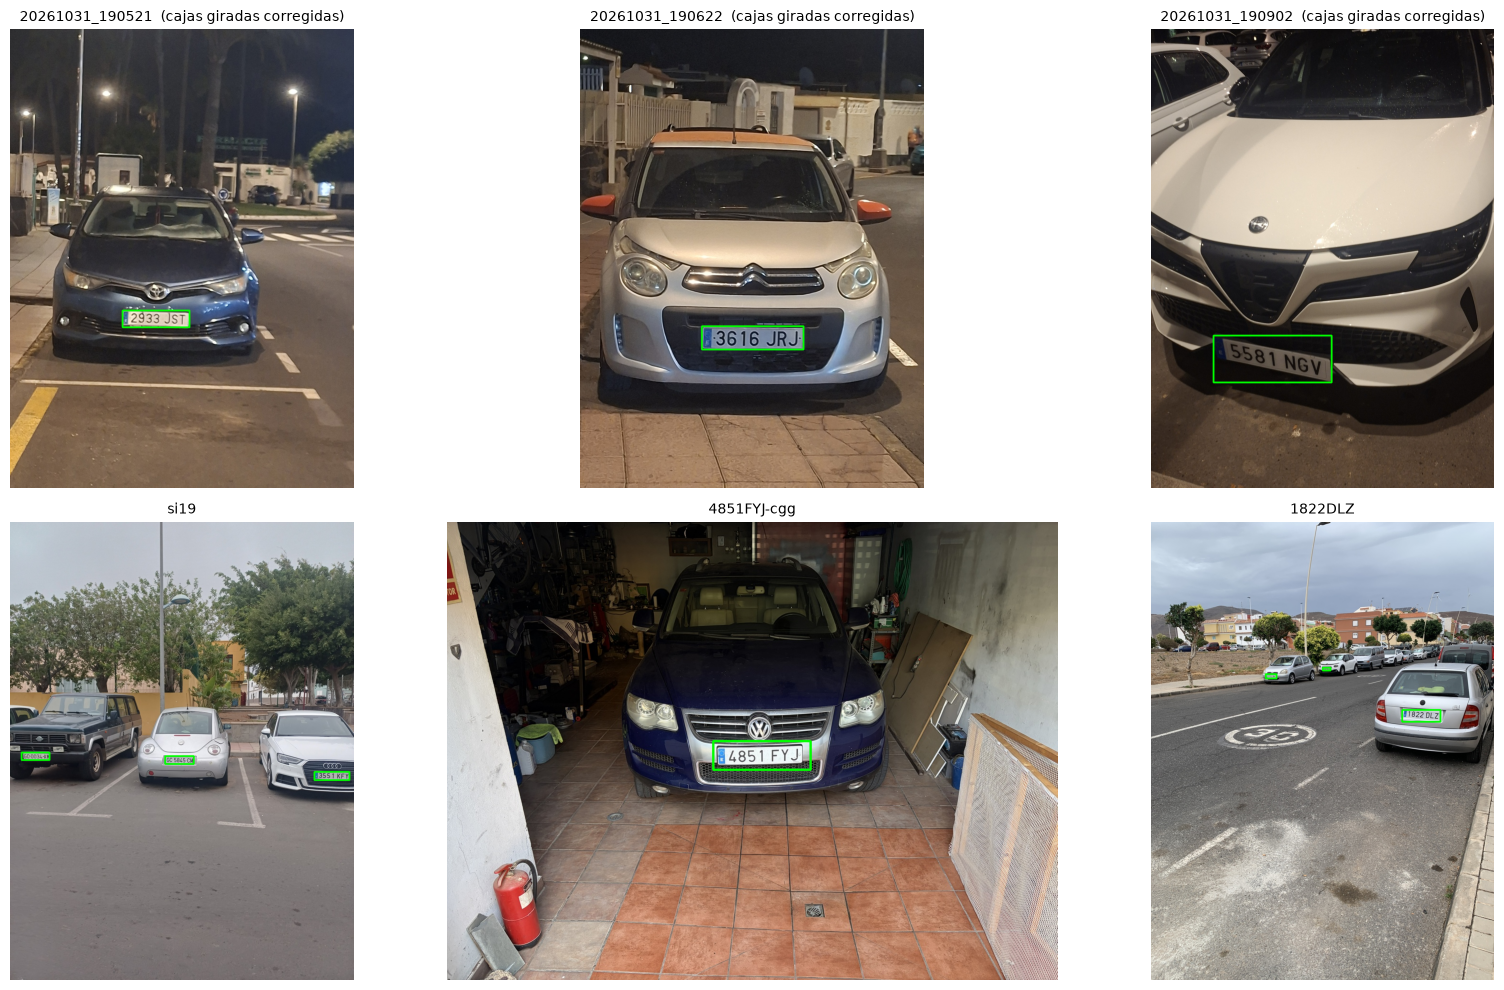

In [13]:
# ===== 2.1 Dataset de YOLO11s con la misma división que RT-DETRv2-S =====
# Misma preparación que la Fase 1 de VC_P4_RTDETR (rotación EXIF, reescalado a 1280 px, corrección de las cajas
# anotadas sobre la foto sin girar y división por bloques 60/15/25 con SEED = 42), pero guardando el formato de YOLO:
#   P4_dataset/{train,val,test}/images/<foto>.jpg  y  P4_dataset/{train,val,test}/labels/<foto>.txt
# Así los dos detectores se entrenan, validan y prueban con las mismas imágenes y las mismas cajas.
import json, random, shutil, statistics
from collections import Counter
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Dataset original sin dividir: fotos + un JSON de anotaciones por foto (mismo nombre)
DATASET_DIR = Path(r"C:/Uni/VC/P4_dataset_original")
IMG_DIR     = DATASET_DIR / "images"
ANN_DIR     = DATASET_DIR / "annotations"
# Salida: la carpeta a la que apunta YOLO/train.yaml (path: C:/Uni/VC/P4_dataset)
OUT_DIR     = Path(r"C:/Uni/VC/P4_dataset")
DATASET_COCO = Path("Dataset_coco")                    # opcional: solo para comprobar que la división coincide

# Mismos parámetros que la Fase 1 de RT-DETR
MAX_SIDE = 1280                                        # lado mayor tras reescalar (no amplía)
BLOCK    = 10                                          # fotos seguidas que van juntas al mismo conjunto
SPLITS   = {"train": 0.60, "val": 0.15, "test": 0.25}
SEED     = 42
IMG_EXTS = {".jpg", ".jpeg", ".png"}
CONFIG   = {"max_side": MAX_SIDE, "block": BLOCK, "splits": SPLITS, "seed": SEED}
MARCA    = OUT_DIR / "division.json"                   # registra con qué parámetros se generó la carpeta


def rect_to_xyxy(rect, W, H):
    """[cx, cy, w, h] normalizado -> esquinas en píxeles, recortadas a la imagen."""
    cx, cy, w, h = rect
    return (max(0.0, (cx - w / 2) * W), max(0.0, (cy - h / 2) * H),
            min(float(W), (cx + w / 2) * W), min(float(H), (cy + h / 2) * H))


def load_resized(path):
    """Abre la imagen, aplica la rotación EXIF y reduce el lado mayor a MAX_SIDE (no amplía)."""
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    W, H = im.size
    scale = min(1.0, MAX_SIDE / max(W, H))
    if scale < 1.0:
        im = im.resize((round(W * scale), round(H * scale)), Image.LANCZOS)
    return im


# --- 0) Si P4_dataset tiene otra división (p. ej. la 70/15/15 anterior), se borra antes de empezar ---
previa = json.loads(MARCA.read_text(encoding="utf-8")) if MARCA.exists() else None
if previa is None or previa.get("config") != CONFIG:
    for split in SPLITS:
        if (OUT_DIR / split).exists():
            shutil.rmtree(OUT_DIR / split)
            print(f"Borrada la división anterior: {OUT_DIR / split}")
OUT_DIR.mkdir(parents=True, exist_ok=True)
MARCA.write_text(json.dumps({"config": CONFIG, "completo": False}, indent=2), encoding="utf-8")

# --- 1) Lista de fotos con anotación, ordenada por nombre SIN distinguir mayúsculas ---
# Es el orden en que Windows ordena las rutas en la Fase 1 de RT-DETR. Se fija explícitamente porque con un
# orden que distingue mayúsculas (Linux/macOS) cambian los bloques y más de 1000 fotos acabarían en otro conjunto.
img_paths = sorted((p for p in IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXTS), key=lambda p: p.name.lower())
sin_anotacion = [p.name for p in img_paths if not (ANN_DIR / f"{p.stem}.json").exists()]
img_paths = [p for p in img_paths if (ANN_DIR / f"{p.stem}.json").exists()]

# --- 2) División por bloques de BLOCK fotos consecutivas (mismo coche/escena), igual que en RT-DETR ---
blocks = [img_paths[i:i + BLOCK] for i in range(0, len(img_paths), BLOCK)]
order = list(range(len(blocks)))
random.Random(SEED).shuffle(order)
n_total = len(img_paths)
limits = {"train": SPLITS["train"] * n_total, "val": (SPLITS["train"] + SPLITS["val"]) * n_total}
split_of, assigned = {}, 0
for b in order:
    split = "train" if assigned < limits["train"] else "val" if assigned < limits["val"] else "test"
    for p in blocks[b]:
        split_of[p.name] = split
    assigned += len(blocks[b])
assert all(len({split_of[p.name] for p in blk}) == 1 for blk in blocks)   # cada bloque, entero en un conjunto

# --- 3) Imágenes reescaladas + etiquetas YOLO (clase cx cy w h normalizados) ---
for split in SPLITS:
    for sub in ("images", "labels"):
        (OUT_DIR / split / sub).mkdir(parents=True, exist_ok=True)

resumen = {s: Counter() for s in SPLITS}
esperados = {s: set() for s in SPLITS}
for k, img_path in enumerate(img_paths, 1):
    split = split_of[img_path.name]
    out_img = OUT_DIR / split / "images" / f"{img_path.stem}.jpg"
    out_lab = OUT_DIR / split / "labels" / f"{img_path.stem}.txt"
    esperados[split] |= {out_img.name, out_lab.name}
    if out_img.exists():                                 # ya procesada en una ejecución anterior
        W, H = Image.open(out_img).size
    else:
        im = load_resized(img_path)
        tmp = out_img.with_suffix(".tmp")
        im.save(tmp, "JPEG", quality=95)                 # sin EXIF: la orientación ya está aplicada
        tmp.replace(out_img)                             # si se interrumpe, no queda una imagen a medias
        W, H = im.size

    objs = json.loads((ANN_DIR / f"{img_path.stem}.json").read_text(encoding="utf-8"))
    # Fotos con EXIF de orientación 6 anotadas sobre la imagen SIN girar: todas sus cajas salen verticales.
    # Se detectan por la mediana de la proporción y se llevan a la imagen girada (como en la Fase 1 de RT-DETR).
    orient = Image.open(img_path).getexif().get(0x0112, 1)
    ratios = [o["rectangle"][2] * W / (o["rectangle"][3] * H) for o in objs if o["rectangle"][2] * o["rectangle"][3] > 0]
    girada = orient == 6 and bool(ratios) and statistics.median(ratios) < 0.6

    lineas = []
    for obj in objs:
        cx, cy, rw, rh = obj["rectangle"]
        rect = [1 - cy, cx, rh, rw] if girada else obj["rectangle"]
        x1, y1, x2, y2 = rect_to_xyxy(rect, W, H)
        if x2 - x1 < 1 or y2 - y1 < 1:                   # caja degenerada: se descarta (como en RT-DETR)
            resumen[split]["cajas descartadas"] += 1
            continue
        # Misma caja (redondeada a 0.01 px) que la anotación COCO de RT-DETR, pasada a formato YOLO
        x, y, w, h = (round(v, 2) for v in (x1, y1, x2 - x1, y2 - y1))
        lineas.append(f"0 {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}")
        plate = obj.get("plate")
        resumen[split]["legibles"] += plate is not None and plate.strip().upper() not in ("", "NONE")
    out_lab.write_text("".join(l + "\n" for l in lineas), encoding="utf-8")

    resumen[split]["imágenes"] += 1
    resumen[split]["matrículas"] += len(lineas)
    resumen[split]["sin matrículas"] += not lineas
    resumen[split]["con cajas giradas"] += girada
    if k % 250 == 0 or k == n_total:
        print(f"  {k}/{n_total} imágenes procesadas")

# Restos que no pertenecen a esta división (temporales, caché de etiquetas de Ultralytics...)
for split in SPLITS:
    for sub in ("images", "labels"):
        for f in (OUT_DIR / split / sub).iterdir():
            if f.name not in esperados[split]:
                f.unlink()
    for cache in (OUT_DIR / split).glob("*.cache"):
        cache.unlink()
MARCA.write_text(json.dumps({"config": CONFIG, "completo": True}, indent=2), encoding="utf-8")

# --- 4) Resumen y comprobaciones ---
print(f"\nSin anotación (excluidas): {sin_anotacion or 'ninguna'}")
print(f"{'conjunto':<6} {'imágenes':>9} {'%':>6} {'matrículas':>11} {'legibles':>9} {'sin matr.':>10} {'giradas':>8} {'descart.':>9}")
for split, c in resumen.items():
    print(f"{split:<6} {c['imágenes']:>9} {100 * c['imágenes'] / n_total:>5.1f}% {c['matrículas']:>11} {c['legibles']:>9} "
          f"{c['sin matrículas']:>10} {c['con cajas giradas']:>8} {c['cajas descartadas']:>9}")

for split in SPLITS:
    imgs = {f.stem for f in (OUT_DIR / split / "images").iterdir()}
    labs = {f.stem for f in (OUT_DIR / split / "labels").iterdir()}
    assert imgs == labs, f"{split}: imágenes y etiquetas no coinciden"

# Comprobación con la división de RT-DETR, si está Dataset_coco
if (DATASET_COCO / "annotations").exists():
    split_rt = {}
    for split in SPLITS:
        d = json.loads((DATASET_COCO / "annotations" / f"instances_{split}.json").read_text(encoding="utf-8"))
        split_rt.update({i["orig_name"]: split for i in d["images"]})
    distintas = [n for n, s in split_of.items() if split_rt.get(n) != s]
    print(f"\nComprobación con Dataset_coco: {len(split_of) - len(distintas)}/{len(split_of)} fotos en el mismo conjunto"
          + ("  ✓" if not distintas else f"  ✗ distintas: {distintas[:10]}"))

# --- 5) Visualización de etiquetas YOLO en train (las 3 primeras con cajas giradas corregidas + 3 al azar) ---
def dibujar_yolo(split, stem):
    img = cv2.cvtColor(cv2.imread(str(OUT_DIR / split / "images" / f"{stem}.jpg")), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lw = max(2, round(max(H, W) / 400))
    for linea in (OUT_DIR / split / "labels" / f"{stem}.txt").read_text().splitlines():
        _, cx, cy, w, h = map(float, linea.split())
        cv2.rectangle(img, (int((cx - w / 2) * W), int((cy - h / 2) * H)), (int((cx + w / 2) * W), int((cy + h / 2) * H)),
                      (0, 255, 0), lw + 1)
    return img


def es_girada(p):
    objs = json.loads((ANN_DIR / f"{p.stem}.json").read_text(encoding="utf-8"))
    if Image.open(p).getexif().get(0x0112, 1) != 6:
        return False
    W, H = Image.open(OUT_DIR / split_of[p.name] / "images" / f"{p.stem}.jpg").size
    r = [o["rectangle"][2] * W / (o["rectangle"][3] * H) for o in objs if o["rectangle"][2] * o["rectangle"][3] > 0]
    return bool(r) and statistics.median(r) < 0.6


train_paths = [p for p in img_paths if split_of[p.name] == "train"]
muestra = [p for p in train_paths if es_girada(p)][:3]
muestra += random.Random(SEED).sample([p for p in train_paths if p not in muestra], 6 - len(muestra))
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, p in zip(axes.ravel(), muestra):
    ax.imshow(dibujar_yolo("train", p.stem))
    ax.set_title(f"{p.stem}" + ("  (cajas giradas corregidas)" if es_girada(p) else ""), fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 2.2 Entrenamiento

Se entrena con `YOLO/train.yaml` (dataset de la sección 2.1) y la misma configuración que antes: 50 épocas, 800 px,
lote de 8 y precisión mixta. Los resultados se guardan en `runs/detect/yolo11s_div_rtdetr`, que es la carpeta que
usa la comparativa.

In [14]:
# ===== 2.2 Entrenamiento de YOLO11s =====
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from pathlib import Path
from ultralytics import YOLO

model = YOLO(Path("YOLO/yolo11s.pt"))
model.train(data=Path("YOLO/train.yaml"), epochs=50, imgsz=800, batch=8, amp=True, cache=False, workers=2,
            name="yolo11s_div_rtdetr")         # -> runs/detect/yolo11s_div_rtdetr

New https://pypi.org/project/ultralytics/8.4.211 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.210  Python-3.11.3 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=YOLO\train.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=YOLO\yolo11s.pt, moment

KeyboardInterrupt: 

## 3. Comparativa YOLO11s vs RT-DETRv2-S

Se comparan los dos detectores de matrículas entrenados (50 épocas, entrada 800 px, una clase):

| | YOLO11s | RT-DETRv2-S |
|---|---|---|
| Pesos | `runs/detect/yolo11s_div_rtdetr/weights/best.pt` | `weights/best.pth` (EMA) |
| Dataset | `P4_dataset` (formato YOLO) | `Dataset_coco` (formato COCO) |

**Misma división y mismas cajas.** Los dos datasets salen del mismo proceso (sección 2.1 y Fase 1 de
VC_P4_RTDETR): mismas fotos reescaladas, mismas anotaciones corregidas y misma división 60/15/25 por bloques
(`SEED = 42`). La celda 3.1 lo comprueba. Así los dos modelos se entrenan, eligen su mejor época y se evalúan con
las mismas imágenes: las **600 de test**, que ninguno ha visto.

**Mismo protocolo para los dos.** Mismas imágenes de entrada (`Dataset_coco`, lado mayor 1280 px), mismas
anotaciones de referencia y mismas métricas (pycocotools e IoU ≥ 0.5 para P/R/F1). Cada modelo usa su propio
preprocesado: YOLO reescala con *letterbox* a 800 px de lado mayor y RT-DETR estira la imagen a 800×800.

**Tiempo de inferencia.** Una imagen por llamada (batch 1), en fp32. Incluye el preprocesado, la red y el
postprocesado (con NMS en YOLO; RT-DETR no necesita NMS). No incluye la lectura del disco. Antes de medir se hacen
10 inferencias de calentamiento.

In [7]:
# ===== 3.1 Configuración, carga de ambos modelos y conjuntos de test =====
import os, sys, io, json, time, contextlib
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from pathlib import Path
from collections import defaultdict
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

assert Path("RT-DETR").exists(), "Falta el repositorio de RT-DETR: ejecuta la Fase 0 de VC_P4_RTDETR"
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))   # módulos src.core... del repo
import importlib, utils
importlib.reload(utils)
from utils import cargar_detector_matriculas

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMGSZ  = 800                                         # resolución de entrenamiento de ambos modelos

# YOLO11s
# Entrenamiento de la sección 2.2 (si se ha relanzado, Ultralytics añade un sufijo: se toma el más reciente)
YOLO_RUN     = max((p for p in Path("runs/detect").glob("yolo11s_div_rtdetr*") if (p / "weights" / "best.pt").exists()),
                   key=lambda p: p.stat().st_mtime)
YOLO_WEIGHTS = YOLO_RUN / "weights" / "best.pt"
YOLO_DATASET = Path(r"C:/Uni/VC/P4_dataset")         # dataset de YOLO (sección 2.1)
# RT-DETRv2-S
RT_CFG       = Path("configs/rtdetrv2_r18vd_120e_coco.yml")
RT_WEIGHTS   = Path("weights/best.pth")
RT_LOG       = Path("output/res_800/log.txt")   # una línea JSON por época
DATASET_COCO = Path("Dataset_coco")                  # dataset de RT-DETR (Fase 1 de VC_P4_RTDETR)

OUT_CMP = Path("output/comparativa"); OUT_CMP.mkdir(parents=True, exist_ok=True)
MODELOS = ["YOLO11s", "RT-DETRv2-S"]
COLOR   = {"YOLO11s": "tab:blue", "RT-DETRv2-S": "tab:orange"}

# --- Modelos ---
yolo_model = YOLO(YOLO_WEIGHTS)
rt_model, rt_post, rt_epoca = cargar_detector_matriculas(RT_CFG, RT_WEIGHTS, DEVICE)
rt_model.eval()

# --- Anotaciones de referencia: las de Dataset_coco (train + val + test), comunes a ambos modelos ---
gt_all = {"images": [], "annotations": [], "categories": None}
img_path, split_rt, id_por_nombre = {}, {}, {}
for split in ("train", "val", "test"):
    d = json.loads((DATASET_COCO / "annotations" / f"instances_{split}.json").read_text(encoding="utf-8"))
    gt_all["categories"] = d["categories"]
    gt_all["images"] += d["images"]
    gt_all["annotations"] += d["annotations"]
    for im in d["images"]:
        nombre = Path(im["orig_name"]).stem
        img_path[im["id"]] = DATASET_COCO / f"images_{split}" / im["file_name"]
        split_rt[nombre] = split
        id_por_nombre[nombre] = im["id"]
img_info = {im["id"]: im for im in gt_all["images"]}
gts_por_img = defaultdict(list)
for a in gt_all["annotations"]:
    gts_por_img[a["image_id"]].append(a)

# Partición de cada foto en la división de YOLO (por nombre de fichero, sin extensión)
split_yolo = {p.stem: s for s in ("train", "val", "test") for p in (YOLO_DATASET / s / "images").iterdir()}

# --- Comprobación: misma división en los dos datasets ---
distintas = [n for n in split_rt if split_yolo.get(n) != split_rt[n]]
if distintas:
    print(f"AVISO: {len(distintas)} fotos están en otro conjunto en P4_dataset (p. ej. {distintas[:5]}). "
          "Ejecuta la sección 2.1 y vuelve a entrenar YOLO. Se evalúa solo con las fotos de test comunes.")
else:
    print(f"Misma división en P4_dataset y Dataset_coco: {len(split_rt)} fotos  ✓")

# --- Conjunto de test (el de ambos modelos) ---
test_yolo  = sorted(id_por_nombre[n] for n, s in split_yolo.items() if s == "test" and n in id_por_nombre)
test_rt    = sorted(id_por_nombre[n] for n, s in split_rt.items() if s == "test")
test_comun = sorted(set(test_yolo) & set(test_rt))     # con la misma división, es el test completo
a_inferir  = test_comun

n_mat = lambda ids: sum(len(gts_por_img[i]) for i in ids)
print(f"Test: {len(test_comun)} imágenes, {n_mat(test_comun)} matrículas "
      f"({sum(a.get('legible', True) for i in test_comun for a in gts_por_img[i])} legibles)")
print(f"YOLO11s: {YOLO_WEIGHTS} | dispositivo: {DEVICE}")
print(f"RT-DETRv2-S: best.pth de la época {rt_epoca + 1 if rt_epoca is not None else '?'}")

Misma división en P4_dataset y Dataset_coco: 2418 fotos  ✓
Test: 600 imágenes, 1324 matrículas (791 legibles)
YOLO11s: runs\detect\yolo11s_div_rtdetr\weights\best.pt | dispositivo: cuda
RT-DETRv2-S: best.pth de la época 47


In [8]:
# ===== 3.2 Inferencia de ambos modelos y medición de tiempos =====
DEVICE_YOLO = "0" if DEVICE.type == "cuda" else "cpu"


def pred_yolo(bgr):
    """YOLO11s: letterbox a IMGSZ, red y NMS. conf=0.001 e iou=0.7, como en la validación de Ultralytics."""
    r = yolo_model.predict(bgr, imgsz=IMGSZ, conf=0.001, iou=0.7, max_det=100, device=DEVICE_YOLO, verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()


@torch.no_grad()
def pred_rtdetr(bgr):
    """RT-DETRv2-S: mismo preprocesado que su validación (imagen estirada a IMGSZ x IMGSZ, escala [0, 1]).
    Devuelve sus 100 consultas con score, sin umbral (no necesita NMS)."""
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((IMGSZ, IMGSZ), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    _, boxes, scores = rt_post(rt_model(x), torch.tensor([[w, h]], device=DEVICE))
    return boxes[0].cpu().numpy(), scores[0].cpu().numpy()


def sincronizar():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def inferir(pred_fn, ids, n_calentamiento=10):
    """Detecciones (formato de resultados COCO), tiempo por imagen en ms y VRAM extra usada al inferir (MB)."""
    for i in ids[:n_calentamiento]:
        pred_fn(cv2.imread(str(img_path[i])))
    base = 0
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); base = torch.cuda.memory_allocated()
    dets, tiempos = [], []
    for i in ids:
        bgr = cv2.imread(str(img_path[i]))            # la lectura del disco no se cronometra
        sincronizar(); t0 = time.perf_counter()
        boxes, scores = pred_fn(bgr)
        sincronizar(); tiempos.append(1000 * (time.perf_counter() - t0))
        dets += [{"image_id": i, "category_id": 0, "score": float(s),
                  "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)]}
                 for (x1, y1, x2, y2), s in zip(boxes, scores)]
    vram = (torch.cuda.max_memory_allocated() - base) / 2**20 if DEVICE.type == "cuda" else float("nan")
    return dets, np.array(tiempos), vram


DETS, TIEMPOS, VRAM = {}, {}, {}
for nombre, fn in (("YOLO11s", pred_yolo), ("RT-DETRv2-S", pred_rtdetr)):
    DETS[nombre], TIEMPOS[nombre], VRAM[nombre] = inferir(fn, a_inferir)
    t = TIEMPOS[nombre]
    print(f"{nombre:<12} {len(t)} imágenes | media {t.mean():.1f} ms | mediana {np.median(t):.1f} ms | "
          f"{1000 / t.mean():.1f} FPS | {len(DETS[nombre])} detecciones")
    (OUT_CMP / f"detecciones_{nombre}.json").write_text(json.dumps(DETS[nombre]), encoding="utf-8")

YOLO11s      600 imágenes | media 17.6 ms | mediana 16.7 ms | 57.0 FPS | 8075 detecciones
RT-DETRv2-S  600 imágenes | media 47.3 ms | mediana 45.9 ms | 21.1 FPS | 60000 detecciones


In [9]:
# ===== 3.3 Métricas: tablas comparativas =====
def iou_xywh(b, G):
    """IoU entre una caja [x, y, w, h] y un array de cajas G (N x 4)."""
    x1, y1 = np.maximum(b[0], G[:, 0]), np.maximum(b[1], G[:, 1])
    x2 = np.minimum(b[0] + b[2], G[:, 0] + G[:, 2]); y2 = np.minimum(b[1] + b[3], G[:, 1] + G[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / (b[2] * b[3] + G[:, 2] * G[:, 3] - inter + 1e-9)


def coco_eval(ids, dets, solo_legibles=False):
    """AP/AR COCO con pycocotools sobre las imágenes ids. Con solo_legibles, las matrículas ilegibles se marcan
    iscrowd=1: detectarlas o no detectarlas no cuenta (igual que en la Fase 4 de VC_P4_RTDETR)."""
    ids = set(ids)
    gt = {"images": [img_info[i] for i in ids], "categories": gt_all["categories"],
          "annotations": [dict(a, iscrowd=int(solo_legibles and not a.get("legible", True)))
                          for i in ids for a in gts_por_img[i]]}
    with contextlib.redirect_stdout(io.StringIO()):
        G = COCO(); G.dataset = gt; G.createIndex()
        E = COCOeval(G, G.loadRes([d for d in dets if d["image_id"] in ids]), "bbox")
        E.evaluate(); E.accumulate(); E.summarize()
    return E.stats                                   # 12 valores; -1 si no hay matrículas de ese tamaño


def curvas(ids, dets, iou_thr=0.5):
    """Emparejamiento voraz por score (como COCO) con IoU >= iou_thr.
    Devuelve las curvas P, R y F1 frente al umbral de confianza y, por matrícula real, su alto (px)
    y el score de la detección que la acierta (0 si ninguna)."""
    por_img = defaultdict(list)
    for d in dets:
        por_img[d["image_id"]].append(d)
    scores, aciertos, alto_gt, score_gt = [], [], [], []
    for i in ids:
        g = np.array([a["bbox"] for a in gts_por_img[i]], float).reshape(-1, 4)
        score_i = np.zeros(len(g))
        for d in sorted(por_img[i], key=lambda d: -d["score"]):
            ok = False
            if len(g):
                iou = iou_xywh(d["bbox"], g); iou[score_i > 0] = -1      # cada matrícula se acierta una vez
                j = iou.argmax()
                if iou[j] >= iou_thr:
                    score_i[j] = d["score"]; ok = True
            scores.append(d["score"]); aciertos.append(ok)
        alto_gt += list(g[:, 3]); score_gt += list(score_i)
    o = np.argsort(-np.array(scores), kind="stable")
    s, tp = np.array(scores)[o], np.array(aciertos)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    P, R = ctp / np.maximum(ctp + cfp, 1), ctp / max(len(alto_gt), 1)
    return {"score": s, "P": P, "R": R, "F1": 2 * P * R / np.maximum(P + R, 1e-9), "tp": ctp, "fp": cfp,
            "n_gt": len(alto_gt), "alto_gt": np.array(alto_gt), "score_gt": np.array(score_gt)}


def en_umbral(c, conf):
    """P, R, F1, TP, FP y FN quedándose con las detecciones de score >= conf."""
    k = int((c["score"] >= conf).sum()) - 1
    if k < 0:
        return dict(P=np.nan, R=0.0, F1=0.0, TP=0, FP=0, FN=c["n_gt"])
    return dict(P=c["P"][k], R=c["R"][k], F1=c["F1"][k], TP=int(c["tp"][k]), FP=int(c["fp"][k]),
                FN=c["n_gt"] - int(c["tp"][k]))


STATS, STATS_LEG, CURVAS, OPT = {}, {}, {}, {}
for m in MODELOS:
    STATS[m]     = coco_eval(test_comun, DETS[m])
    STATS_LEG[m] = coco_eval(test_comun, DETS[m], solo_legibles=True)
    CURVAS[m]    = c = curvas(test_comun, DETS[m])
    k = int(np.argmax(c["F1"]))
    OPT[m] = dict(conf=float(c["score"][k]), **en_umbral(c, c["score"][k]))

# --- Tabla 1: precisión de la detección en test ---
filas = {
    "AP 0.50:0.95": lambda m: STATS[m][0],
    "AP 0.50": lambda m: STATS[m][1],
    "AP 0.75": lambda m: STATS[m][2],
    "AP pequeñas (< 32² px)": lambda m: STATS[m][3],
    "AP medianas": lambda m: STATS[m][4],
    "AP grandes (> 96² px)": lambda m: STATS[m][5],
    "AR@100 0.50:0.95": lambda m: STATS[m][8],
    "AP 0.50:0.95 (solo legibles)": lambda m: STATS_LEG[m][0],
    "AP 0.50 (solo legibles)": lambda m: STATS_LEG[m][1],
    "Umbral de F1 máximo": lambda m: OPT[m]["conf"],
    "Precisión (umbral F1 máx.)": lambda m: OPT[m]["P"],
    "Recall (umbral F1 máx.)": lambda m: OPT[m]["R"],
    "F1 máximo": lambda m: OPT[m]["F1"],
    "TP (umbral F1 máx.)": lambda m: OPT[m]["TP"],
    "FP (umbral F1 máx.)": lambda m: OPT[m]["FP"],
    "FN (umbral F1 máx.)": lambda m: OPT[m]["FN"],
    "Precisión (conf 0.5)": lambda m: en_umbral(CURVAS[m], 0.5)["P"],
    "Recall (conf 0.5)": lambda m: en_umbral(CURVAS[m], 0.5)["R"],
    "F1 (conf 0.5)": lambda m: en_umbral(CURVAS[m], 0.5)["F1"],
}
def formatear(df, decimales=3):
    """Copia para mostrar: enteros sin decimales, el resto con `decimales`, y '—' donde no hay dato."""
    def f(v):
        if isinstance(v, str):
            return v
        if pd.isna(v):
            return "—"
        return f"{int(v)}" if float(v).is_integer() and abs(v) >= 1 else f"{v:.{decimales}f}"
    return df.apply(lambda col: col.map(f))


menor_mejor = {"FP (umbral F1 máx.)", "FN (umbral F1 máx.)"}
tabla_det = pd.DataFrame({m: {k: f(m) for k, f in filas.items()} for m in MODELOS}).replace(-1, np.nan)


def mejor(fila):
    if fila.name.startswith("Umbral") or fila.isna().any():
        return "—"
    if np.isclose(fila.iloc[0], fila.iloc[1]):
        return "empate"
    return (fila.idxmin() if fila.name in menor_mejor else fila.idxmax())


tabla_det["Mejor"] = tabla_det.apply(mejor, axis=1)
print(f"Tabla 1 · Detección en test ({len(test_comun)} imágenes, {n_mat(test_comun)} matrículas; "
      f"IoU ≥ 0.5 para P/R/F1)")
display(formatear(tabla_det))

# --- Tabla 2: coste computacional y entrenamiento ---
def gflops(model):
    """GFLOPs de una pasada 1x3xIMGSZxIMGSZ (FlopCounterMode de torch; mismo criterio para los dos)."""
    try:
        from torch.utils.flop_counter import FlopCounterMode
        p = next(model.parameters())
        x = torch.zeros(1, 3, IMGSZ, IMGSZ, device=p.device, dtype=p.dtype)
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            model(x)
        return fc.get_total_flops() / 1e9
    except Exception as e:
        print("No se pudieron contar los FLOPs:", e)
        return np.nan


res_yolo = pd.read_csv(YOLO_RUN / "results.csv"); res_yolo.columns = res_yolo.columns.str.strip()
log_rt = pd.DataFrame([json.loads(l) for l in RT_LOG.read_text(encoding="utf-8").splitlines() if l.strip()])
log_rt["epoch"] += 1                                   # el repo cuenta las épocas desde 0
log_rt["AP50:95"] = log_rt["test_coco_eval_bbox"].str[0]
log_rt["AP50"]    = log_rt["test_coco_eval_bbox"].str[1]
log_rt["AR100"]   = log_rt["test_coco_eval_bbox"].str[8]

n_params = {"YOLO11s": sum(p.numel() for p in yolo_model.model.parameters()),
            "RT-DETRv2-S": sum(p.numel() for p in rt_model.parameters())}
coste = {}
for m, red in (("YOLO11s", yolo_model.model), ("RT-DETRv2-S", rt_model)):
    t = TIEMPOS[m]
    coste[m] = {
        "Parámetros (M)": n_params[m] / 1e6,
        f"GFLOPs ({IMGSZ}×{IMGSZ})": gflops(red),
        "Pesos fp32 (MB)": n_params[m] * 4 / 2**20,
        "Tiempo medio (ms/img)": t.mean(),
        "Tiempo mediana (ms/img)": np.median(t),
        "Tiempo p95 (ms/img)": np.percentile(t, 95),
        "FPS (media)": 1000 / t.mean(),
        "VRAM extra al inferir (MB)": VRAM[m],
    }
coste["YOLO11s"].update({"Imágenes de train": sum(s == "train" for s in split_yolo.values()),
                         "Épocas": len(res_yolo),
                         "Mejor época (mAP50-95 en val)": int(res_yolo.loc[res_yolo["metrics/mAP50-95(B)"].idxmax(), "epoch"]),
                         "mAP50-95 máx. en val": res_yolo["metrics/mAP50-95(B)"].max(),
                         "Tiempo de entrenamiento (h)": res_yolo["time"].iloc[-1] / 3600})
coste["RT-DETRv2-S"].update({"Imágenes de train": sum(s == "train" for s in split_rt.values()),
                             "Épocas": len(log_rt),
                             "Mejor época (mAP50-95 en val)": int(log_rt.loc[log_rt["AP50:95"].idxmax(), "epoch"]),
                             "mAP50-95 máx. en val": log_rt["AP50:95"].max(),
                             "Tiempo de entrenamiento (h)": np.nan})   # el log del repo no guarda el tiempo
tabla_coste = pd.DataFrame(coste)
print(f"\nTabla 2 · Coste computacional y entrenamiento (inferencia en {DEVICE}, batch 1, fp32)")
display(formatear(tabla_coste, decimales=2).replace("—", "no registrado"))
print("Nota: la mAP de validación es del mismo conjunto de val, pero cada modelo la calcula con su propio evaluador "
      "(Ultralytics / pycocotools); las cifras comparables son las de test de la Tabla 1.")

for nombre, t in (("deteccion", tabla_det), ("coste", tabla_coste)):
    t.to_csv(OUT_CMP / f"tabla_{nombre}.csv", encoding="utf-8")

Tabla 1 · Detección en test (600 imágenes, 1324 matrículas; IoU ≥ 0.5 para P/R/F1)


,YOLO11s,RT-DETRv2-S,Mejor
AP 0.50:0.95,0.409,0.411,RT-DETRv2-S
AP 0.50,0.724,0.739,RT-DETRv2-S
AP 0.75,0.416,0.415,YOLO11s
AP pequeñas (< 32² px),0.260,0.255,YOLO11s
AP medianas,0.629,0.619,YOLO11s
AP grandes (> 96² px),0.721,0.768,RT-DETRv2-S
AR@100 0.50:0.95,0.493,0.528,RT-DETRv2-S
AP 0.50:0.95 (solo legibles),0.574,0.572,YOLO11s
AP 0.50 (solo legibles),0.939,0.935,YOLO11s
Umbral de F1 máximo,0.345,0.560,—



Tabla 2 · Coste computacional y entrenamiento (inferencia en cuda, batch 1, fp32)


,YOLO11s,RT-DETRv2-S
Parámetros (M),9.43,21.84
GFLOPs (800×800),33.58,91.10
Pesos fp32 (MB),35.97,83.33
Tiempo medio (ms/img),17.56,47.30
Tiempo mediana (ms/img),16.75,45.89
Tiempo p95 (ms/img),22.32,54.67
FPS (media),56.95,21.14
VRAM extra al inferir (MB),66.41,147.33
Imágenes de train,1458,1458
Épocas,50,50


Nota: la mAP de validación es del mismo conjunto de val, pero cada modelo la calcula con su propio evaluador (Ultralytics / pycocotools); las cifras comparables son las de test de la Tabla 1.


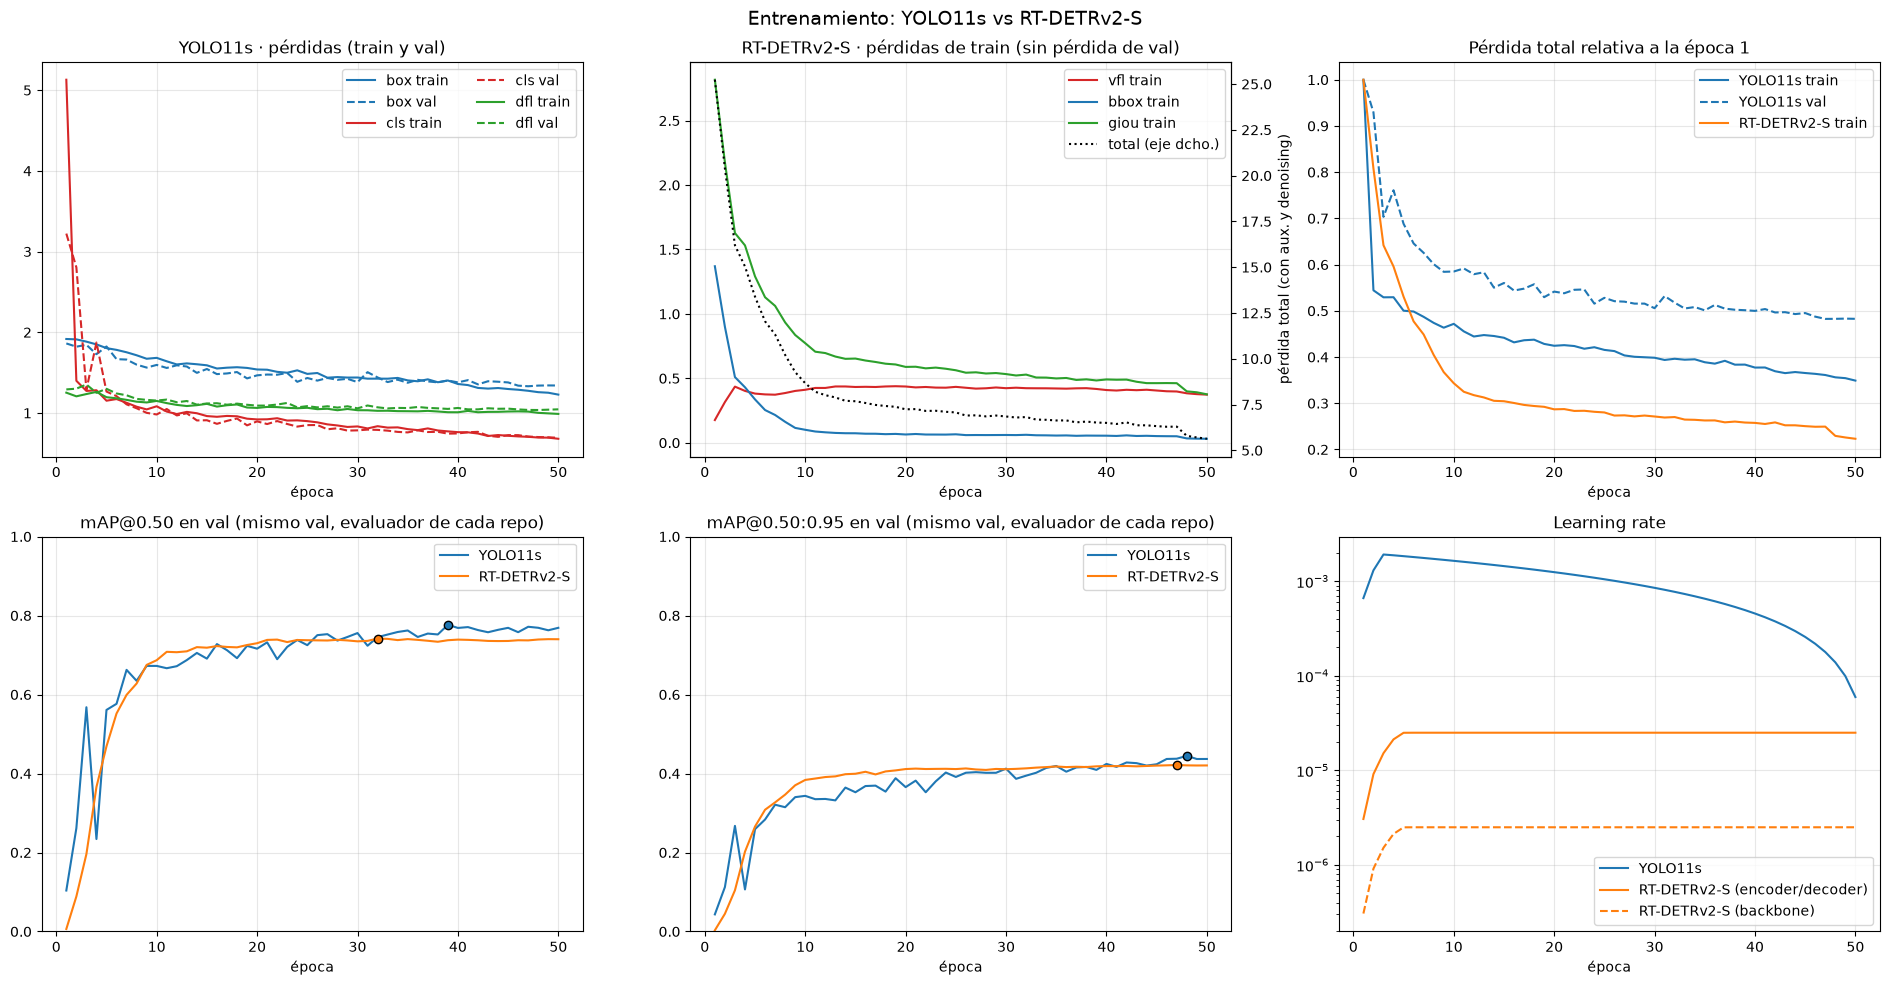

In [10]:
# ===== 3.4 Curvas de entrenamiento: pérdidas, mAP de validación y learning rate =====
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
ep_y = res_yolo["epoch"]

# (a) YOLO: pérdidas de train (continua) y val (discontinua)
ax = axes[0, 0]
for comp, col in (("box", "tab:blue"), ("cls", "tab:red"), ("dfl", "tab:green")):
    ax.plot(ep_y, res_yolo[f"train/{comp}_loss"], color=col, label=f"{comp} train")
    ax.plot(ep_y, res_yolo[f"val/{comp}_loss"], color=col, ls="--", label=f"{comp} val")
ax.set_title("YOLO11s · pérdidas (train y val)"); ax.set_xlabel("época"); ax.legend(ncol=2)

# (b) RT-DETR: pérdidas de la cabeza principal (el repo no calcula pérdida en val)
ax = axes[0, 1]
for comp, col in (("vfl", "tab:red"), ("bbox", "tab:blue"), ("giou", "tab:green")):
    ax.plot(log_rt["epoch"], log_rt[f"train_loss_{comp}"], color=col, label=f"{comp} train")
ax2 = ax.twinx()
ax2.plot(log_rt["epoch"], log_rt["train_loss"], color="k", ls=":", label="total (eje dcho.)")
ax2.set_ylabel("pérdida total (con aux. y denoising)")
ax.set_title("RT-DETRv2-S · pérdidas de train (sin pérdida de val)"); ax.set_xlabel("época")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2)

# (c) Pérdida total normalizada (época 1 = 1): las escalas no son comparables, la velocidad de convergencia sí
ax = axes[0, 2]
tot_tr = res_yolo[[f"train/{c}_loss" for c in ("box", "cls", "dfl")]].sum(axis=1)
tot_va = res_yolo[[f"val/{c}_loss" for c in ("box", "cls", "dfl")]].sum(axis=1)
ax.plot(ep_y, tot_tr / tot_tr.iloc[0], color=COLOR["YOLO11s"], label="YOLO11s train")
ax.plot(ep_y, tot_va / tot_va.iloc[0], color=COLOR["YOLO11s"], ls="--", label="YOLO11s val")
ax.plot(log_rt["epoch"], log_rt["train_loss"] / log_rt["train_loss"].iloc[0], color=COLOR["RT-DETRv2-S"],
        label="RT-DETRv2-S train")
ax.set_title("Pérdida total relativa a la época 1"); ax.set_xlabel("época"); ax.legend()

# (d) y (e) mAP de validación por época
for ax, (col_y, col_rt, titulo) in zip(axes[1, :2], (("metrics/mAP50(B)", "AP50", "mAP@0.50 en val"),
                                                     ("metrics/mAP50-95(B)", "AP50:95", "mAP@0.50:0.95 en val"))):
    ax.plot(ep_y, res_yolo[col_y], color=COLOR["YOLO11s"], label="YOLO11s")
    ax.plot(log_rt["epoch"], log_rt[col_rt], color=COLOR["RT-DETRv2-S"], label="RT-DETRv2-S")
    for serie_x, serie_y, m in ((ep_y, res_yolo[col_y], "YOLO11s"), (log_rt["epoch"], log_rt[col_rt], "RT-DETRv2-S")):
        k = serie_y.idxmax()
        ax.scatter(serie_x[k], serie_y[k], color=COLOR[m], zorder=3, edgecolor="k")
    ax.set_title(f"{titulo} (mismo val, evaluador de cada repo)"); ax.set_xlabel("época"); ax.set_ylim(0, 1); ax.legend()

# (f) Learning rate
ax = axes[1, 2]
ax.plot(ep_y, res_yolo["lr/pg0"], color=COLOR["YOLO11s"], label="YOLO11s")
# El log del repo guarda el lr del primer grupo de parámetros (backbone); encoder/decoder usa 10 veces más (config)
ax.plot(log_rt["epoch"], log_rt["train_lr"] * 10, color=COLOR["RT-DETRv2-S"], label="RT-DETRv2-S (encoder/decoder)")
ax.plot(log_rt["epoch"], log_rt["train_lr"], color=COLOR["RT-DETRv2-S"], ls="--", label="RT-DETRv2-S (backbone)")
ax.set_yscale("log"); ax.set_title("Learning rate"); ax.set_xlabel("época"); ax.legend()

for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.suptitle("Entrenamiento: YOLO11s vs RT-DETRv2-S", fontsize=14)
plt.tight_layout(); fig.savefig(OUT_CMP / "curvas_entrenamiento.png", dpi=120); plt.show()

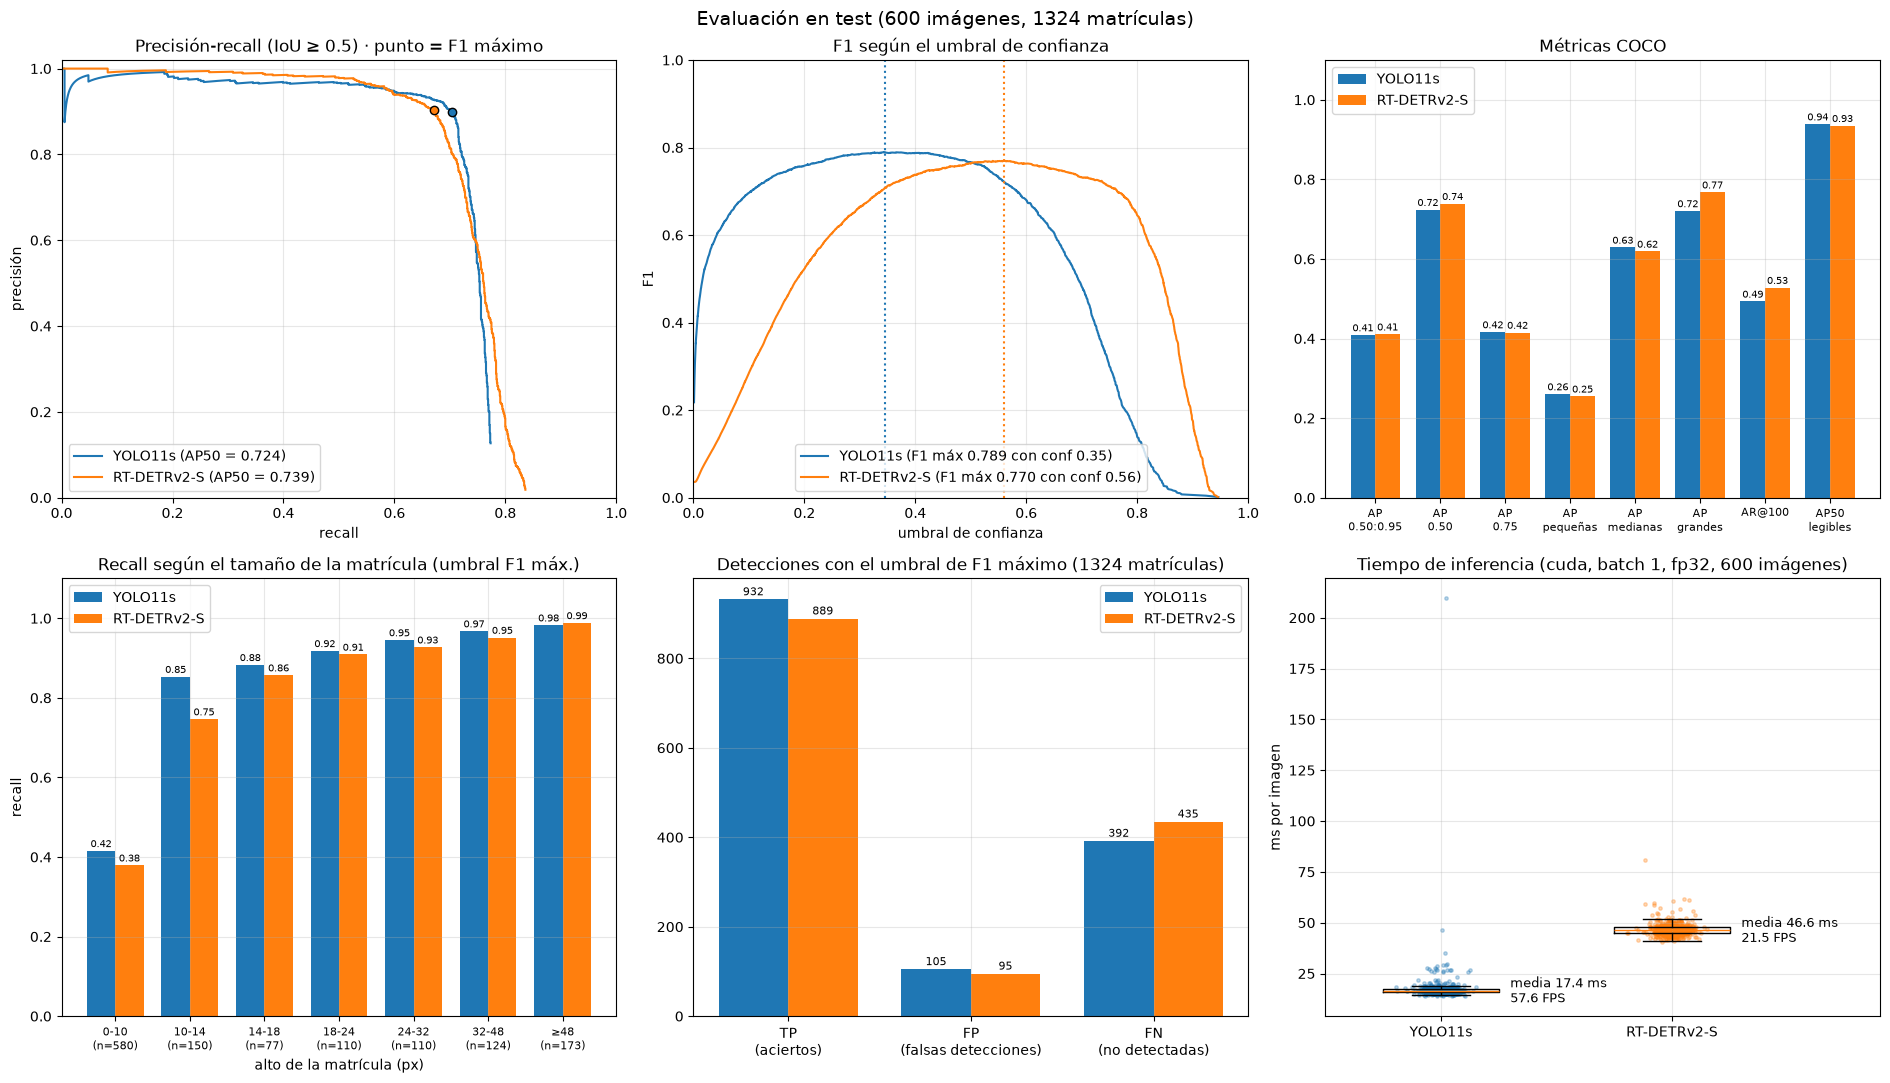

In [5]:
# ===== 3.5 Gráficas de evaluación en test =====
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# (a) Curva precisión-recall (IoU >= 0.5)
ax = axes[0, 0]
for m in MODELOS:
    c = CURVAS[m]
    ax.plot(c["R"], c["P"], color=COLOR[m], label=f"{m} (AP50 = {STATS[m][1]:.3f})")
    ax.scatter(OPT[m]["R"], OPT[m]["P"], color=COLOR[m], edgecolor="k", zorder=3)
ax.set_xlabel("recall"); ax.set_ylabel("precisión"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precisión-recall (IoU ≥ 0.5) · punto = F1 máximo"); ax.legend(loc="lower left")

# (b) F1 frente al umbral de confianza
ax = axes[0, 1]
for m in MODELOS:
    c = CURVAS[m]
    ax.plot(c["score"], c["F1"], color=COLOR[m], label=f"{m} (F1 máx {OPT[m]['F1']:.3f} con conf {OPT[m]['conf']:.2f})")
    ax.axvline(OPT[m]["conf"], color=COLOR[m], ls=":")
ax.set_xlabel("umbral de confianza"); ax.set_ylabel("F1"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("F1 según el umbral de confianza"); ax.legend(loc="lower center")

# (c) Métricas COCO en barras
ax = axes[0, 2]
nombres = ["AP\n0.50:0.95", "AP\n0.50", "AP\n0.75", "AP\npequeñas", "AP\nmedianas", "AP\ngrandes", "AR@100", "AP50\nlegibles"]
valores = {m: [STATS[m][i] for i in (0, 1, 2, 3, 4, 5, 8)] + [STATS_LEG[m][1]] for m in MODELOS}
x = np.arange(len(nombres)); w = 0.38
for k, m in enumerate(MODELOS):
    v = np.where(np.array(valores[m]) < 0, np.nan, valores[m])
    barras = ax.bar(x + (k - 0.5) * w, v, w, color=COLOR[m], label=m)
    ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x, nombres, fontsize=8); ax.set_ylim(0, 1.1); ax.set_title("Métricas COCO"); ax.legend()

# (d) Recall por alto de la matrícula (px en la imagen de 1280 px de lado mayor), con el umbral de F1 máximo
ax = axes[1, 0]
BINS = [0, 10, 14, 18, 24, 32, 48, np.inf]
etiquetas = [f"{BINS[i]:.0f}-{BINS[i + 1]:.0f}" if np.isfinite(BINS[i + 1]) else f"≥{BINS[i]:.0f}" for i in range(len(BINS) - 1)]
alto = CURVAS[MODELOS[0]]["alto_gt"]                    # el mismo orden de matrículas para los dos modelos
tramo = np.digitize(alto, BINS) - 1
cuenta = np.bincount(tramo, minlength=len(etiquetas))
x = np.arange(len(etiquetas))
for k, m in enumerate(MODELOS):
    det = CURVAS[m]["score_gt"] >= OPT[m]["conf"]
    rec = [det[tramo == b].mean() if cuenta[b] else np.nan for b in range(len(etiquetas))]
    barras = ax.bar(x + (k - 0.5) * w, rec, w, color=COLOR[m], label=m)
    ax.bar_label(barras, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(x, [f"{e}\n(n={n})" for e, n in zip(etiquetas, cuenta)], fontsize=8)
ax.set_xlabel("alto de la matrícula (px)"); ax.set_ylabel("recall"); ax.set_ylim(0, 1.1)
ax.set_title("Recall según el tamaño de la matrícula (umbral F1 máx.)"); ax.legend()

# (e) Aciertos y errores con el umbral de F1 máximo
ax = axes[1, 1]
tipos = ["TP", "FP", "FN"]
x = np.arange(len(tipos))
for k, m in enumerate(MODELOS):
    barras = ax.bar(x + (k - 0.5) * w, [OPT[m][t] for t in tipos], w, color=COLOR[m], label=m)
    ax.bar_label(barras, fontsize=8, padding=1)
ax.set_xticks(x, ["TP\n(aciertos)", "FP\n(falsas detecciones)", "FN\n(no detectadas)"])
ax.set_title(f"Detecciones con el umbral de F1 máximo ({n_mat(test_comun)} matrículas)"); ax.legend()

# (f) Distribución del tiempo de inferencia
ax = axes[1, 2]
ax.boxplot([TIEMPOS[m] for m in MODELOS], showfliers=False, widths=0.5)
for k, m in enumerate(MODELOS, start=1):
    t = TIEMPOS[m]
    ax.scatter(np.random.default_rng(0).normal(k, 0.05, len(t)), t, s=6, alpha=0.3, color=COLOR[m])
    ax.text(k + 0.3, np.median(t), f"media {t.mean():.1f} ms\n{1000 / t.mean():.1f} FPS", va="center", fontsize=9)
ax.set_xlim(0.5, 2.9); ax.set_xticks([1, 2], MODELOS); ax.set_ylabel("ms por imagen")
ax.set_title(f"Tiempo de inferencia ({DEVICE.type}, batch 1, fp32, {len(a_inferir)} imágenes)")

for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.suptitle(f"Evaluación en test ({len(test_comun)} imágenes, {n_mat(test_comun)} matrículas)", fontsize=14)
plt.tight_layout(); fig.savefig(OUT_CMP / "evaluacion_test_comun.png", dpi=120); plt.show()

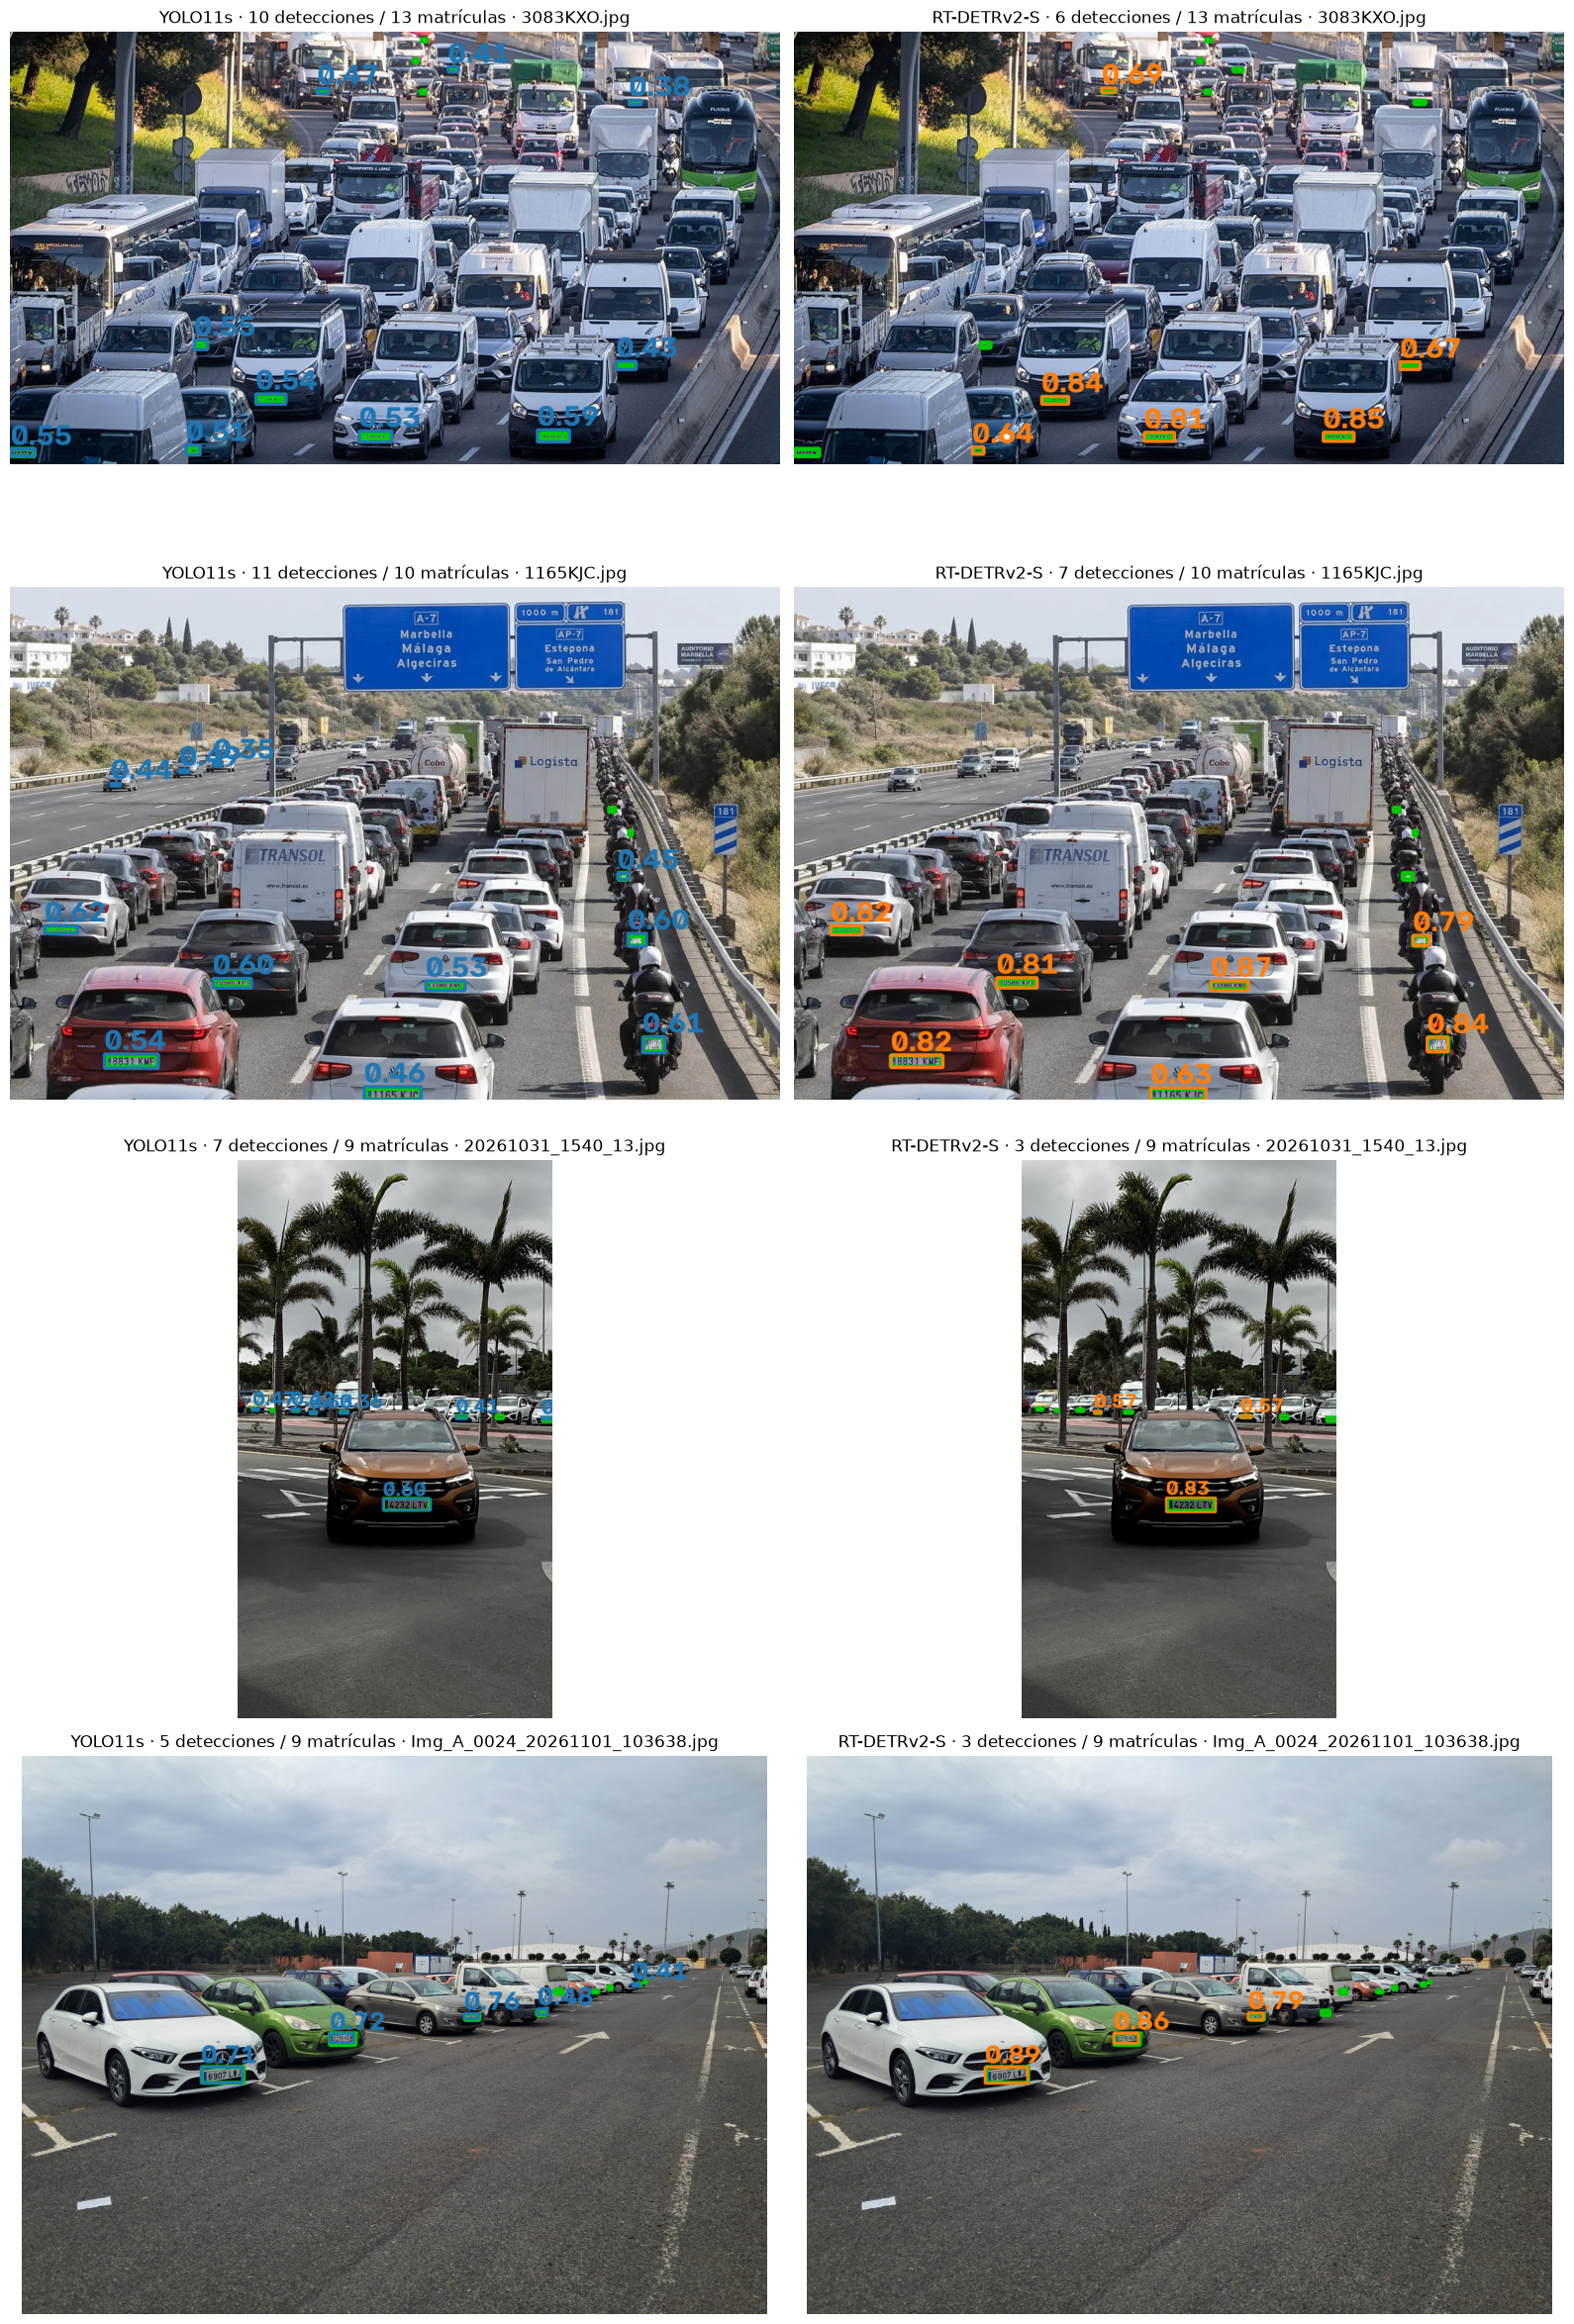

Resumen en test (600 imágenes):
  AP 0.50:0.95   YOLO11s 0.409 | RT-DETRv2-S 0.411 -> mejor: RT-DETRv2-S
  AP 0.50        YOLO11s 0.724 | RT-DETRv2-S 0.739 -> mejor: RT-DETRv2-S
  F1 máximo      YOLO11s 0.789 | RT-DETRv2-S 0.770 -> mejor: YOLO11s
  Velocidad      YOLO11s es 2.7x más rápido (17.4 vs 46.6 ms/img)
  Tamaño         YOLO11s 9.4 M parámetros | RT-DETRv2-S 21.8 M


In [6]:
# ===== 3.6 Ejemplos de test: cajas reales (verde) y predicciones de cada modelo =====
# Cada modelo usa su umbral de F1 máximo. Se eligen las imágenes con más matrículas.
N_EJEMPLOS = 4
ejemplos = sorted(test_comun, key=lambda i: -len(gts_por_img[i]))[:N_EJEMPLOS]
fig, axes = plt.subplots(len(ejemplos), 2, figsize=(16, 6 * len(ejemplos)), squeeze=False)
for fila, i in zip(axes, ejemplos):
    base = cv2.cvtColor(cv2.imread(str(img_path[i])), cv2.COLOR_BGR2RGB)
    lw = max(2, round(max(base.shape[:2]) / 400))
    for ax, m in zip(fila, MODELOS):
        img = base.copy()
        for a in gts_por_img[i]:
            x, y, w_, h_ = map(int, a["bbox"])
            cv2.rectangle(img, (x, y), (x + w_, y + h_), (0, 200, 0), lw + 2)
        color = tuple(int(255 * v) for v in plt.matplotlib.colors.to_rgb(COLOR[m]))
        n = 0
        for d in DETS[m]:
            if d["image_id"] == i and d["score"] >= OPT[m]["conf"]:
                x, y, w_, h_ = map(int, d["bbox"]); n += 1
                cv2.rectangle(img, (x, y), (x + w_, y + h_), color, lw)
                cv2.putText(img, f"{d['score']:.2f}", (x, max(y - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * lw, color, lw)
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{m} · {n} detecciones / {len(gts_por_img[i])} matrículas · {img_info[i]['file_name']}")
plt.tight_layout(); plt.show()

# --- Resumen ---
print(f"Resumen en test ({len(test_comun)} imágenes):")
for clave, desc in (("AP 0.50:0.95", "AP 0.50:0.95"), ("AP 0.50", "AP 0.50"), ("F1 máximo", "F1 máximo")):
    v = tabla_det.loc[clave, MODELOS]
    v = v.astype(float)
    ganador = "empate" if np.isclose(v.iloc[0], v.iloc[1]) else v.idxmax()
    print(f"  {desc:<14} YOLO11s {v['YOLO11s']:.3f} | RT-DETRv2-S {v['RT-DETRv2-S']:.3f} -> mejor: {ganador}")
tm = {m: TIEMPOS[m].mean() for m in MODELOS}
rapido = min(tm, key=tm.get); lento = max(tm, key=tm.get)
print(f"  Velocidad      {rapido} es {tm[lento] / tm[rapido]:.1f}x más rápido ({tm[rapido]:.1f} vs {tm[lento]:.1f} ms/img)")
print(f"  Tamaño         YOLO11s {n_params['YOLO11s'] / 1e6:.1f} M parámetros | RT-DETRv2-S {n_params['RT-DETRv2-S'] / 1e6:.1f} M")